In [1]:
!pip install requests lxml html5lib matplotlib pandas


In [2]:
import pandas as pd
import requests

url = "https://en.wikipedia.org/wiki/List_of_countries_by_carbon_dioxide_emissions_per_capita"

headers = {
    "User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/120.0.0.0 Safari/537.36"
}

response = requests.get(url, headers=headers)
response.raise_for_status()

# MultiIndex tabloyu oku
df = pd.read_html(response.text, header=[0,1])[0]

print("✅ Veri çekildi")
df.head()


✅ Veri çekildi


/var/folders/0y/k1jq8l8j3z719f74v53gcz8m0000gn/T/ipykernel_3567/2716256365.py:16: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  df = pd.read_html(response.text, header=[0,1])[0]


Location % of global average Emissions per capita (tons per year)  \
         Location % of global average                                 2023   
0           World                100%                                 4.86   
1  European Union                117%                                 5.66   
2      Palau[n 4]               1288%                                62.59   
3           Qatar                896%                                43.55   
4          Kuwait                512%                                24.90   

          % change from 2000  
     2000 % change from 2000  
0    4.19               +16%  
1    8.32               −32%  
2  110.66               −43%  
3   53.61               −19%  
4   26.56                −6%

In [3]:
# Çok katmanlı sütunları tek katmana indiriyoruz
df.columns = ['_'.join(col).strip() for col in df.columns.values]

# Yeni sütun isimleri
rename_map = {
    "Location_Location": "Country",
    "Emissions per capita (tons per year)_2023": "Emissions_2023",
    "Emissions per capita (tons per year)_2000": "Emissions_2000",
    "% change from 2000_% change from 2000": "Pct_Change_2000_to_2023"
}

df = df.rename(columns=rename_map)
df = df[list(rename_map.values())]
df.head()


,Country,Emissions_2023,Emissions_2000,Pct_Change_2000_to_2023
0,World,4.86,4.19,+16%
1,European Union,5.66,8.32,−32%
2,Palau[n 4],62.59,110.66,−43%
3,Qatar,43.55,53.61,−19%
4,Kuwait,24.90,26.56,−6%


In [4]:
# Gereksiz karakterleri kaldır
for col in ["Emissions_2000", "Emissions_2023", "Pct_Change_2000_to_2023"]:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace("−", "-", regex=False)  # Unicode eksi işaretini düzelt
        .str.replace("%", "", regex=False)
        .str.replace("—", "", regex=False)
        .str.replace("–", "-", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

# Sayısala çevir
df["Emissions_2000"] = pd.to_numeric(df["Emissions_2000"], errors="coerce")
df["Emissions_2023"] = pd.to_numeric(df["Emissions_2023"], errors="coerce")
df["Pct_Change_2000_to_2023"] = pd.to_numeric(df["Pct_Change_2000_to_2023"], errors="coerce")

# Boş satırları at
df = df.dropna(subset=["Emissions_2000", "Emissions_2023"])

print("✅ Temizlik tamamlandı")
df.head(10)


✅ Temizlik tamamlandı


,Country,Emissions_2023,Emissions_2000,Pct_Change_2000_to_2023
0,World,4.86,4.19,16
1,European Union,5.66,8.32,-32
2,Palau[n 4],62.59,110.66,-43
3,Qatar,43.55,53.61,-19
4,Kuwait,24.90,26.56,-6
5,Brunei,21.12,18.23,16
6,New Caledonia,20.90,10.22,105
7,Bahrain,20.70,26.74,-23
8,United Arab Emirates,20.22,28.04,-28
9,Trinidad and Tobago,19.71,15.09,31


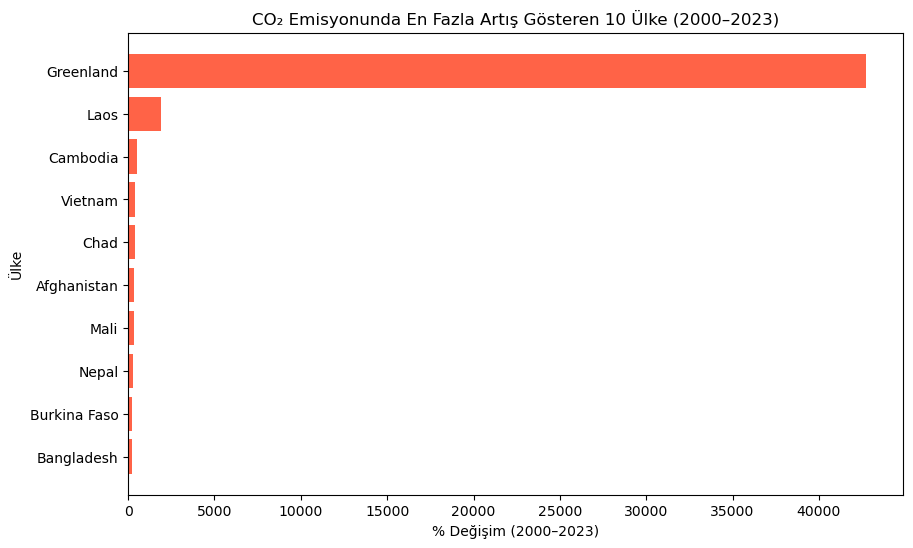

In [5]:
import matplotlib.pyplot as plt

top10 = df.sort_values("Pct_Change_2000_to_2023", ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(top10["Country"], top10["Pct_Change_2000_to_2023"], color="tomato")
plt.xlabel("% Değişim (2000–2023)")
plt.ylabel("Ülke")
plt.title("CO₂ Emisyonunda En Fazla Artış Gösteren 10 Ülke (2000–2023)")
plt.gca().invert_yaxis()
plt.show()


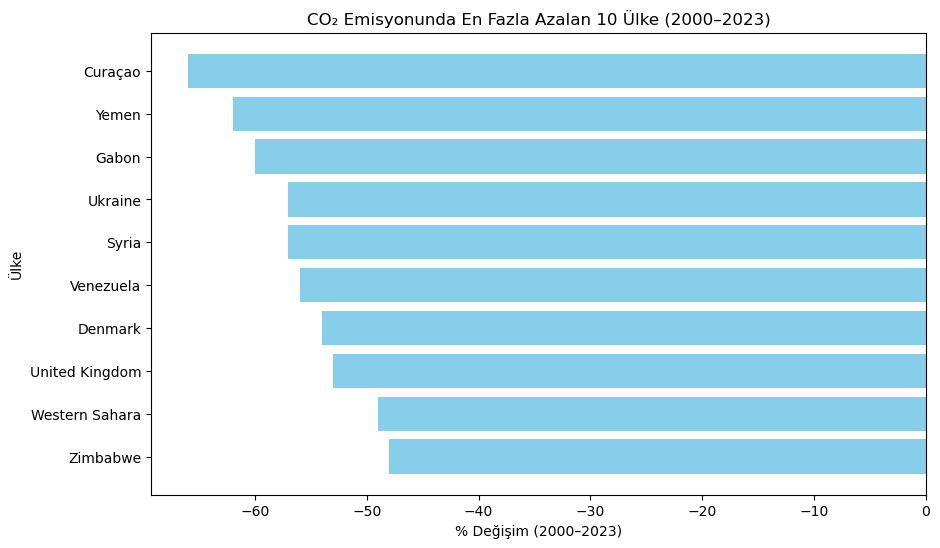

In [6]:
bottom10 = df.sort_values("Pct_Change_2000_to_2023", ascending=True).head(10)

plt.figure(figsize=(10,6))
plt.barh(bottom10["Country"], bottom10["Pct_Change_2000_to_2023"], color="skyblue")
plt.xlabel("% Değişim (2000–2023)")
plt.ylabel("Ülke")
plt.title("CO₂ Emisyonunda En Fazla Azalan 10 Ülke (2000–2023)")
plt.gca().invert_yaxis()
plt.show()


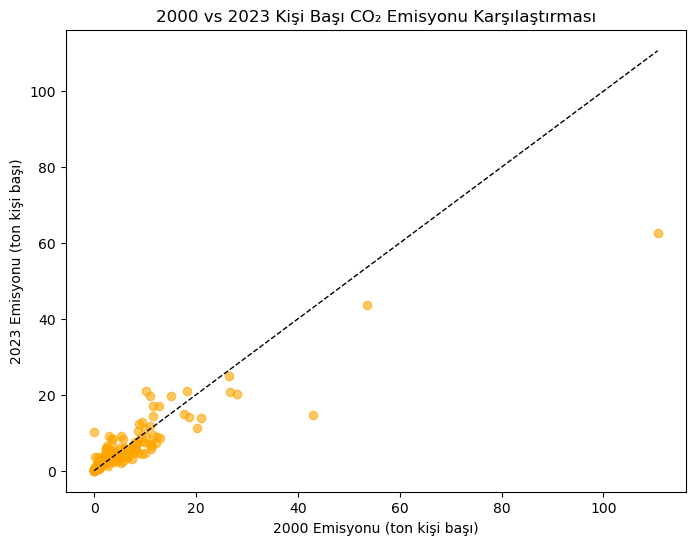

In [7]:
plt.figure(figsize=(8,6))
plt.scatter(df["Emissions_2000"], df["Emissions_2023"], color="orange", alpha=0.6)
plt.plot([0, df["Emissions_2000"].max()], [0, df["Emissions_2000"].max()], 'k--', lw=1)
plt.xlabel("2000 Emisyonu (ton kişi başı)")
plt.ylabel("2023 Emisyonu (ton kişi başı)")
plt.title("2000 vs 2023 Kişi Başı CO₂ Emisyonu Karşılaştırması")
plt.show()
